# IR 与 Raman：简正模式和谱线展宽

这是明确给出参数的物理教学模拟，没有使用实验测量，也不作为模型基准。可修改参数并重新执行，观察结果变化。

In [1]:
import io, json, sys
from pathlib import Path
from IPython.display import display, SVG
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'openmolspec_bench').is_dir())
sys.path.insert(0, str(root/'src'))
import matplotlib.pyplot as plt
from openmolspec.plotting import figure_style
figure_style()
blue, teal, grey = '#397BA6', '#178F88', '#A8B3BF'


Simulated mode frequencies (cm^-1): [720.0, 1050.0, 1650.0, 2950.0, 3100.0]
Gaussian sigma (cm^-1): 12.0


/mnt/shared-storage-user/xiejiaqing/OpenMolSpec/studio/.runtime/docs-sphinx/lib/python3.13/site-packages/IPython/core/events.py:101: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  func(*args, **kwargs)
/mnt/shared-storage-user/xiejiaqing/OpenMolSpec/studio/.runtime/docs-sphinx/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


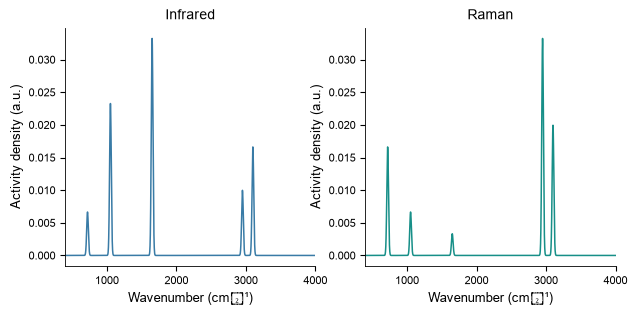

In [2]:
import numpy as np
axis = np.linspace(400, 4000, 3601)
frequencies = np.array([720., 1050., 1650., 2950., 3100.])
ir_activity = np.array([.2,.7,1.,.3,.5])
raman_activity = np.array([.5,.2,.1,1.,.6])
sigma = 12.
gaussians = np.exp(-.5*((axis[:,None]-frequencies[None,:])/sigma)**2)/(sigma*np.sqrt(2*np.pi))
ir = gaussians@ir_activity
raman = gaussians@raman_activity
assert np.isclose(np.trapezoid(ir, axis), ir_activity.sum(), rtol=.002)
fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.1))
for ax, values, strengths, title, color in zip(axes,[ir,raman],[ir_activity,raman_activity],['Infrared','Raman'],[blue,teal]):
    ax.plot(axis, values, color=color, lw=1.1)
    ax.set(xlabel='Wavenumber (cm⁻¹)', ylabel='Activity density (a.u.)', title=title, xlim=(400,4000))
print('Simulated mode frequencies (cm^-1):', frequencies.tolist())
print('Gaussian sigma (cm^-1):', sigma)

/tmp/ipykernel_1266/2404734664.py:3: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.tight_layout(w_pad=2)
/tmp/ipykernel_1266/2404734664.py:5: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.savefig(image,format='svg',metadata={'Date':None})


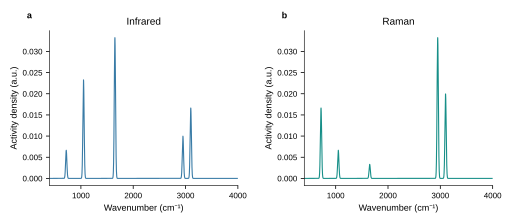

In [3]:
for index, ax in enumerate(axes):
    ax.text(-.12,1.08,chr(97+index),transform=ax.transAxes,fontsize=9,weight='bold')
fig.tight_layout(w_pad=2)
image=io.StringIO()
fig.savefig(image,format='svg',metadata={'Date':None})
display(SVG(image.getvalue()))
plt.close(fig)

[Theory](../theory/index.md) · [Inversion](../inversion/index.md) · [Tutorials](index.md)